# Chapter 4 – Training Models: Exercises

*Hands-On Machine Learning (3rd ed.), Aurélien Géron*

Exercises 1–11 are written answers. Exercise 12 is code (NumPy only, no Scikit-Learn models).

## 1. Millions of features: which Linear Regression training algorithm?

Use **Stochastic GD** or **Mini-batch GD**. **Batch GD** also works if the training set fits in memory.

Do **not** use the Normal Equation or SVD. Their cost grows faster than quadratically with the number of features, so they become far too slow.

## 2. Features with very different scales

**Who suffers:** Gradient Descent. The cost function becomes a long, thin bowl, so GD takes many steps to reach the bottom.

**Fix:** scale the features first (for example with `StandardScaler`).

- The Normal Equation and SVD work fine without scaling.
- Regularized models also need scaling. The penalty hits large weights, so features with small values get unfairly ignored.

## 3. Can GD get stuck in a local minimum with Logistic Regression?

**No.** The log loss cost function is **convex**, so it has only one minimum: the global one.

## 4. Do all GD algorithms reach the same model if run long enough?

**Almost.** On a convex problem with a learning rate that is not too high, they all get close to the global optimum.

But SGD and Mini-batch GD keep jumping around the optimum unless you **slowly reduce the learning rate**. So their final models are slightly different.

## 5. Validation error goes up every epoch

Look at the **training error**:

- **Training error also goes up:** the learning rate is too high and training is diverging. Lower the learning rate.
- **Training error keeps going down:** the model is **overfitting**. Stop training.

## 6. Stop Mini-batch GD as soon as validation error goes up?

**No.** Mini-batch GD is noisy, so the validation error can go up for a moment and then come back down. If you stop right away, you may stop too early.

**Better:** save the best model, keep training, and stop only after many epochs with no improvement ("patience"). Then go back to the best saved model.

## 7. Fastest to get close? Which actually converges?

- **Fastest to get near the optimum:** Stochastic GD (it uses one instance per step). Mini-batch GD with small batches is close behind.
- **Actually converges:** only **Batch GD**, given enough time.
- **Make the others converge:** gradually reduce the learning rate (a learning schedule).

## 8. Polynomial Regression: validation error much higher than training error

The model is **overfitting** (high variance). Three fixes:

1. **Lower the polynomial degree** (fewer degrees of freedom).
2. **Regularize** the model: add an ℓ₂ penalty (Ridge) or an ℓ₁ penalty (Lasso).
3. **Get more training data.**

## 9. Ridge Regression: training and validation errors almost equal and high

High **bias**: the model is **underfitting**.

**Reduce α** (less regularization) so the model can fit the data better.

## 10. Why use…

**a) Ridge instead of plain Linear Regression?**
A little regularization almost always helps the model generalize, so Ridge is a better default.

**b) Lasso instead of Ridge?**
Lasso (ℓ₁) pushes the weights of unimportant features to **exactly zero**. This is automatic feature selection. Use it when you think only a few features matter. If you are not sure, use Ridge.

**c) Elastic Net instead of Lasso?**
Lasso can act erratically when features are strongly correlated, or when there are more features than training instances. Elastic Net is more stable. It adds one more hyperparameter, but `l1_ratio` close to 1 gives you almost-Lasso without the erratic behavior.

## 11. Outdoor/indoor and daytime/nighttime: two Logistic Regression classifiers or one Softmax?

**Two Logistic Regression classifiers.**

Softmax is for classes where each instance belongs to **exactly one** class. Here all four combinations are possible (outdoor + night, indoor + day, …), so these are two separate yes/no questions.

## 12. Batch Gradient Descent with early stopping for Softmax Regression

Rules: **NumPy only**. Scikit-Learn is used only to load the iris dataset.

Plan:
1. Load iris (petal length and width) and add the bias column.
2. Split into train / validation / test by hand.
3. Scale using training-set statistics only.
4. One-hot encode the targets.
5. Train with Batch GD + ℓ₂ regularization + early stopping.
6. Check accuracy and plot the decision boundaries.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.datasets import load_iris  # only used to load the data

### Load the data

In [2]:
iris = load_iris(as_frame=True)
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = iris.target.values
X.shape, y.shape

((150, 2), (150,))

### Split into train / validation / test (60% / 20% / 20%)

In [3]:
rng = np.random.default_rng(42)
idx = rng.permutation(len(X))

n_test = n_valid = int(len(X) * 0.2)
n_train = len(X) - n_test - n_valid

train_idx = idx[:n_train]
valid_idx = idx[n_train:n_train + n_valid]
test_idx = idx[n_train + n_valid:]

X_train, y_train = X[train_idx], y[train_idx]
X_valid, y_valid = X[valid_idx], y[valid_idx]
X_test, y_test = X[test_idx], y[test_idx]
len(X_train), len(X_valid), len(X_test)

(90, 30, 30)

### Scale, then add the bias term

The mean and standard deviation come from the **training set only**, then get applied to all three sets.

In [4]:
mean, std = X_train.mean(axis=0), X_train.std(axis=0)

def prepare(X):
    X_scaled = (X - mean) / std
    return np.c_[np.ones(len(X_scaled)), X_scaled]  # bias column x0 = 1

X_train_b = prepare(X_train)
X_valid_b = prepare(X_valid)
X_test_b = prepare(X_test)
X_train_b[:3]

array([[ 1.        ,  0.5652724 ,  0.84181791],
       [ 1.        , -0.20465625, -0.27646418],
       [ 1.        ,  1.03907465,  0.28267686]])

### One-hot encode the targets

In [5]:
def to_one_hot(y, n_classes):
    return np.eye(n_classes)[y]

n_inputs = X_train_b.shape[1]          # 3 = bias + 2 features
n_outputs = len(np.unique(y_train))    # 3 classes

Y_train = to_one_hot(y_train, n_outputs)
Y_valid = to_one_hot(y_valid, n_outputs)
print(y_train[:5])
print(Y_train[:5])

[1 1 2 0 2]
[[0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 1.]]


### Softmax, loss, and accuracy

Softmax: $\hat p_k = \dfrac{\exp(s_k)}{\sum_j \exp(s_j)}$

Subtracting the largest score in each row before `np.exp` gives the same result but never overflows.

Loss = cross entropy + ℓ₂ penalty (the bias row is not regularized):

$J(\Theta) = -\dfrac{1}{m}\sum_i\sum_k y_k^{(i)}\log \hat p_k^{(i)} + \dfrac{\alpha}{2}\sum_{k}\sum_{j\ge1}\theta_{j,k}^2$

In [6]:
def softmax(logits):
    exps = np.exp(logits - logits.max(axis=1, keepdims=True))
    return exps / exps.sum(axis=1, keepdims=True)

def loss(X, Y_one_hot, Theta, alpha, eps=1e-7):
    P = softmax(X @ Theta)
    xentropy = -(Y_one_hot * np.log(P + eps)).sum(axis=1).mean()
    l2 = 0.5 * (Theta[1:] ** 2).sum()
    return xentropy + alpha * l2

def accuracy(X, y, Theta):
    return (softmax(X @ Theta).argmax(axis=1) == y).mean()

### Train: Batch GD + early stopping

Gradient: $\nabla_\Theta J = \dfrac{1}{m} X^T(\hat P - Y) + \alpha\,\Theta$ (bias row not regularized)

Early stopping keeps the **best** Theta seen so far, and stops after `patience` epochs with no improvement (see answer 6).

In [7]:
eta = 0.5           # learning rate
alpha = 0.01        # l2 regularization strength
n_epochs = 50_001
patience = 200      # epochs to wait for an improvement
m = len(X_train_b)

Theta = rng.standard_normal((n_inputs, n_outputs))
best_loss, best_Theta, best_epoch = np.inf, Theta.copy(), 0
history = []

for epoch in range(n_epochs):
    P = softmax(X_train_b @ Theta)
    gradients = X_train_b.T @ (P - Y_train) / m
    gradients[1:] += alpha * Theta[1:]
    Theta -= eta * gradients

    val_loss = loss(X_valid_b, Y_valid, Theta, alpha)
    history.append(val_loss)
    if val_loss < best_loss:
        best_loss, best_Theta, best_epoch = val_loss, Theta.copy(), epoch
    elif epoch - best_epoch >= patience:
        print(f"Early stopping at epoch {epoch} (best epoch: {best_epoch})")
        break

Theta = best_Theta  # roll back to the best model
print(f"Best validation loss: {best_loss:.4f}")

Early stopping at epoch 346 (best epoch: 146)
Best validation loss: 0.2644


### Validation loss during training

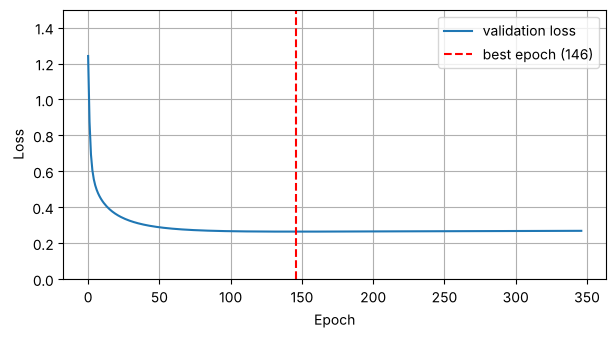

In [8]:
plt.figure(figsize=(7, 3.5))
plt.plot(history, label="validation loss")
plt.axvline(best_epoch, color="red", linestyle="--", label=f"best epoch ({best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.ylim(0, 1.5)
plt.legend()
plt.grid()
plt.show()

### Accuracy

In [9]:
print(f"Train accuracy:      {accuracy(X_train_b, y_train, Theta):.4f}")
print(f"Validation accuracy: {accuracy(X_valid_b, y_valid, Theta):.4f}")
print(f"Test accuracy:       {accuracy(X_test_b, y_test, Theta):.4f}")

Train accuracy:      0.9556
Validation accuracy: 0.9667
Test accuracy:       0.9667


### Decision boundaries

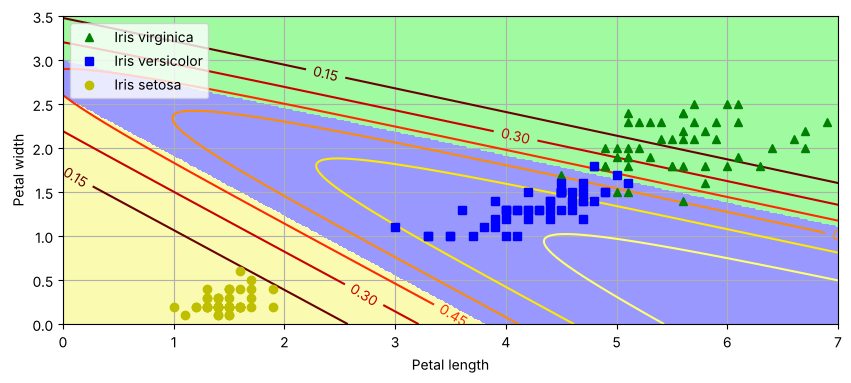

In [10]:
custom_cmap = mpl.colors.ListedColormap(["#fafab0", "#9898ff", "#a0faa0"])

x0, x1 = np.meshgrid(np.linspace(0, 8, 500), np.linspace(0, 3.5, 200))
X_new = np.c_[x0.ravel(), x1.ravel()]
P_new = softmax(prepare(X_new) @ Theta)
zz = P_new.argmax(axis=1).reshape(x0.shape)
zz1 = P_new[:, 1].reshape(x0.shape)

plt.figure(figsize=(10, 4))
plt.contourf(x0, x1, zz, cmap=custom_cmap)
contour = plt.contour(x0, x1, zz1, cmap="hot")
plt.clabel(contour, inline=1)
plt.plot(X[y == 2, 0], X[y == 2, 1], "g^", label="Iris virginica")
plt.plot(X[y == 1, 0], X[y == 1, 1], "bs", label="Iris versicolor")
plt.plot(X[y == 0, 0], X[y == 0, 1], "yo", label="Iris setosa")
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="upper left")
plt.axis([0, 7, 0, 3.5])
plt.grid()
plt.show()

### Notes

- Results change a little with a different random seed. Iris is tiny (only 30 validation and 30 test samples), so one flower more or less moves accuracy by about 3%.
- Differences from the book's solution: this version keeps the **best** Theta (the book keeps the one after the loss started rising), uses **patience** instead of stopping at the first increase, and uses a **stable softmax**.